In [1]:
import sys, os; sys.path.insert(0, os.path.join(os.path.dirname(os.path.abspath('')), 'Utilities'))
import numpy as np
import matplotlib.pyplot as plt
from hyperillumination_utils import *
from kepler_utils import *

In [2]:
# Data from K2-141b (Malavolta et al. 2018, Barragán et al. 2018)
period=0.2803                               #orbital period [days]
rp = 0.02                                   #planet radius [stellar radii / rs]
rs = 0.68                                   # stellar radius [solar radii]
a_AU = 0.007                                #semi-major axis [AU]   
a = AU_to_RS(a_AU, rs)                      #semi-major axis [stellar radii] 
incl = 86.3                                 #orbital inclination [degrees]
ecc = 0.                                    #eccentricity
w = 90.                                     #longitude of periastron [degrees] 
fp = 142e-6                                 #planet-to-star flux ratio / eclipse depth (integrated day-side flux)
T_eff = 4570                                # stellar effective temperature [K]

insolation_penumbra_kopal runtime: 0.0009 s


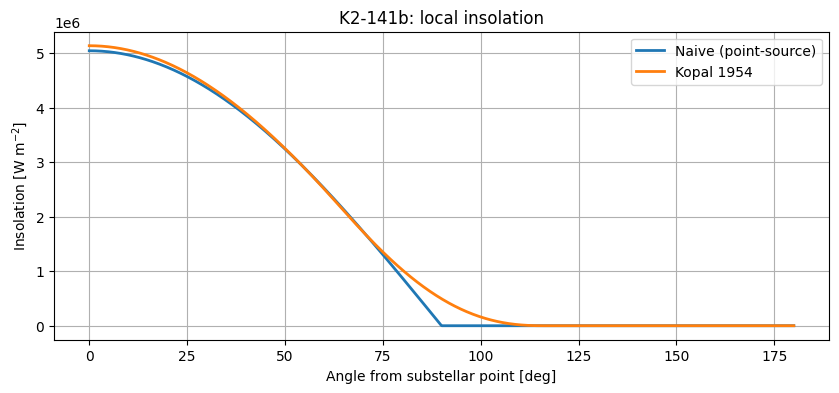

In [3]:
theta = np.linspace(0, 180, 1000)  # angle from substellar point [deg]
insol_naive = naive_insolation(np.radians(theta), 1, a, T_eff)
insol_kopal = insolation_kopal(np.radians(theta), rp, 1, a, T_eff)

plt.figure(figsize=(10, 4))
plt.plot(theta, insol_naive, linewidth=2, label="Naive (point-source)")
plt.plot(theta, insol_kopal, linewidth=2, label="Kopal 1954")

plt.xlabel("Angle from substellar point [deg]")
plt.ylabel(r"Insolation [W m$^{-2}$]")
plt.title("K2-141b: local insolation")
plt.legend()
plt.grid()

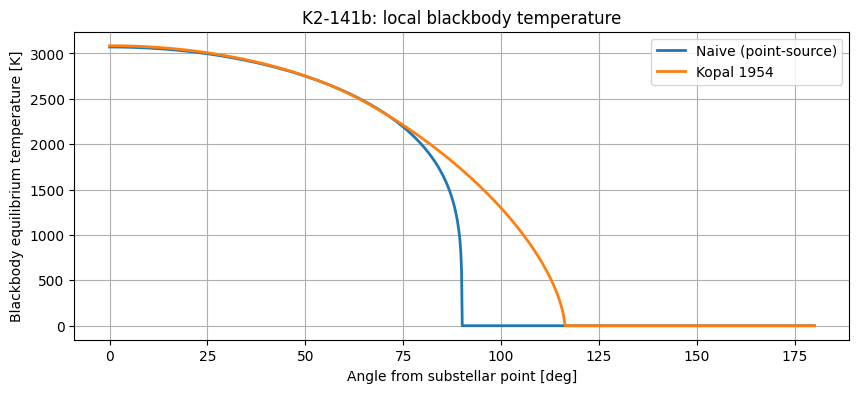

In [4]:
temp_naive = BBtemp_from_insolation(insol_naive)
temp_kopal = BBtemp_from_insolation(insol_kopal)

plt.figure(figsize=(10, 4))
plt.plot(theta, temp_naive, linewidth=2, label="Naive (point-source)")
plt.plot(theta, temp_kopal, linewidth=2, label="Kopal 1954")

plt.xlabel("Angle from substellar point [deg]")
plt.ylabel("Blackbody equilibrium temperature [K]")
plt.title("K2-141b: local blackbody temperature")
plt.legend()
plt.grid()  

In [5]:
fraction_illuminated(rp, 1, a, "extra")

{'fully illuminated': 0.2696025648426177, 'penumbra': 0.45175967677918105}

insolation_penumbra_mask runtime: 0.6800 s
insolation_penumbra_kopal runtime: 0.0008 s
insolation_penumbra_kopal_simpleint runtime: 1.1873 s
insolation_penumbra_kopal_approx runtime: 0.0001 s


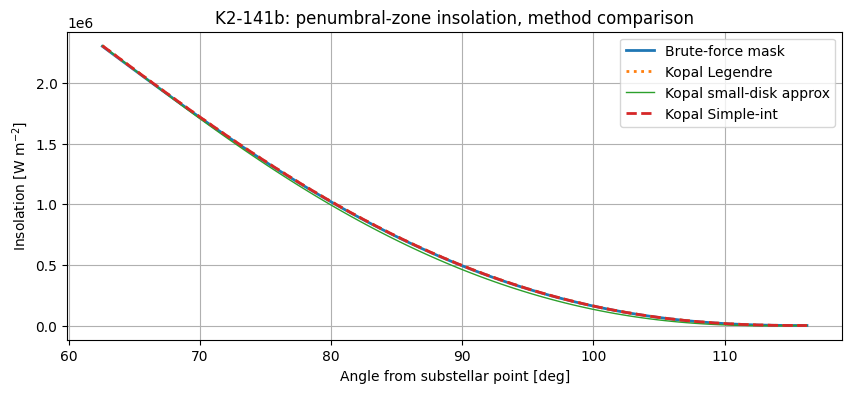

In [6]:
theta_pen = np.linspace(terminator_penumbra(rp, 1, a, unit="deg"), terminator_nightside(rp, 1, a, unit="deg"), 100)

insol_mask = insolation_penumbra_mask(np.radians(theta_pen), rp, 1, a, T_eff)
insol_kopal_legendre = insolation_penumbra_kopal(np.radians(theta_pen), rp, 1, a, T_eff)
insol_kopal_simpleint = insolation_penumbra_kopal_simpleint(np.radians(theta_pen), rp, 1, a, T_eff)
insol_kopal_approx = insolation_penumbra_kopal_approx(np.radians(theta_pen), rp, 1, a, T_eff)

plt.figure(figsize=(10, 4))
plt.plot(theta_pen, insol_mask, linewidth=2, label="Brute-force mask")
plt.plot(theta_pen, insol_kopal_legendre, linewidth=2, linestyle=":", label="Kopal Legendre")
plt.plot(theta_pen, insol_kopal_approx, linewidth=1, label="Kopal small-disk approx")
plt.plot(theta_pen, insol_kopal_simpleint, linewidth=2, linestyle="--", label="Kopal Simple-int")


plt.xlabel("Angle from substellar point [deg]")
plt.ylabel(r"Insolation [W m$^{-2}$]")
plt.title("K2-141b: penumbral-zone insolation, method comparison")
plt.legend()
plt.grid()

/tmp/ipykernel_55483/3842758061.py:2: RuntimeWarning: invalid value encountered in divide
  plt.plot(theta_pen, np.abs(1-insol_mask/insol_kopal_simpleint), linewidth=2, label="Brute-force mask")
/tmp/ipykernel_55483/3842758061.py:3: RuntimeWarning: invalid value encountered in divide
  plt.plot(theta_pen, np.abs(1-insol_kopal_legendre/insol_kopal_simpleint), linewidth=2, linestyle=":", label="Kopal Legendre")


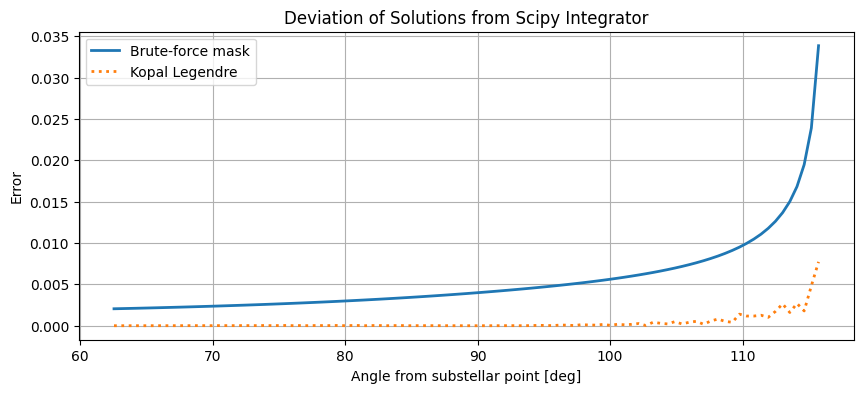

In [12]:
plt.figure(figsize=(10, 4))
plt.plot(theta_pen, np.abs(1-insol_mask/insol_kopal_simpleint), linewidth=2, label="Brute-force mask")
plt.plot(theta_pen, np.abs(1-insol_kopal_legendre/insol_kopal_simpleint), linewidth=2, linestyle=":", label="Kopal Legendre")
#plt.plot(theta_pen, np.abs(1-insol_kopal_approx/insol_kopal_simpleint), linewidth=1, label="Kopal small-disk approx")

plt.xlabel("Angle from substellar point [deg]")
plt.ylabel("Error")
plt.title("Deviation of Solutions from Scipy Integrator")
plt.legend()
plt.grid()